# Uber Fare Prediction

### Objective:
Predict the price of an Uber ride given pickup and drop-off coordinates.

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

### Dataset loading


In [58]:
df = pd.read_csv("uber.csv")
print(df.head())

   Unnamed: 0      key  fare_amount          pickup_datetime  \
0    24238194  52:06.0          7.5  2015-05-07 19:52:06 UTC   
1    27835199  04:56.0          7.7  2009-07-17 20:04:56 UTC   
2    44984355  45:00.0         12.9  2009-08-24 21:45:00 UTC   
3    25894730  22:21.0          5.3  2009-06-26 08:22:21 UTC   
4    17610152  47:00.0         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3                3  
4                5  


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


### Data Cleaning and Preprocessing
Remove missing values, invalid fare amounts, and unrealistic passenger counts.

In [60]:
# Check for missing values
df.isna().sum()


Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [61]:
# Drop rows with missing values
df.dropna(inplace=True)
print("After dropping NaNs:", df.shape)

After dropping NaNs: (199999, 9)


C:\Users\kulka\AppData\Local\Temp\ipykernel_9556\2747212975.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [62]:
# Remove invalid fare amounts (negative or zero)
df = df[df["fare_amount"] > 0]

In [63]:
# Remove invalid passenger counts
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]

### Outlier Detection & Removal

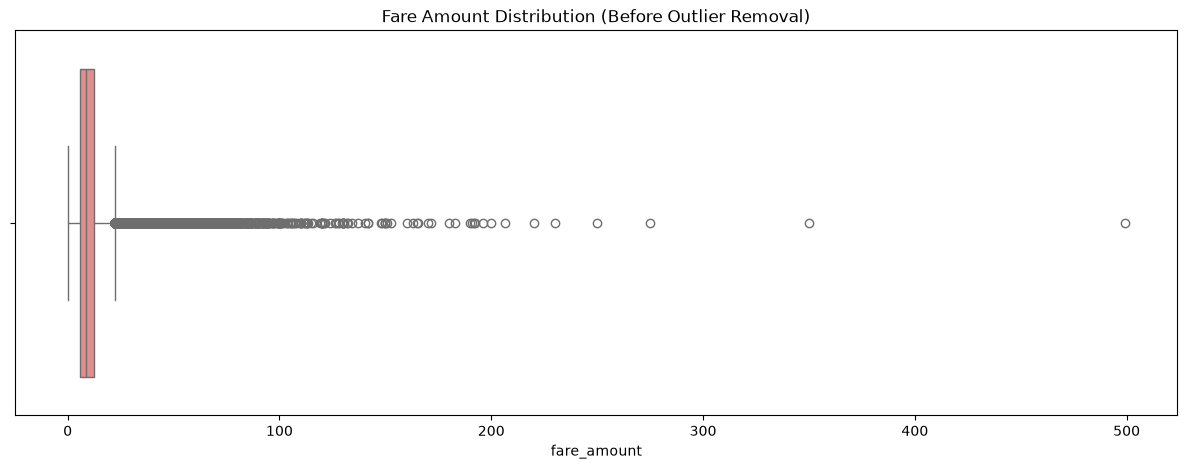

In [64]:
# Boxplot before removing outliers
plt.figure(figsize=(15, 5))
sns.boxplot(x=df["fare_amount"], color="lightcoral")
plt.title("Fare Amount Distribution (Before Outlier Removal)")
plt.show()

In [65]:
# Identify and remove outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

# Keep only data within 1.5 * IQR
df = df[
    (df["fare_amount"] >= Q1 - 1.5 * IQR)
    & (df["fare_amount"] <= Q3 + 1.5 * IQR)
]

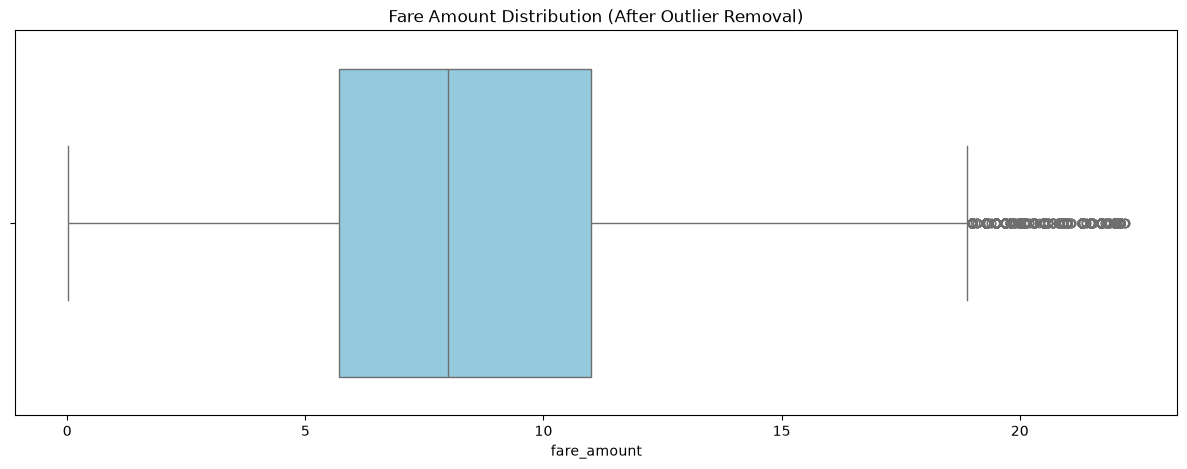

In [66]:
# Boxplot after removing outliers
plt.figure(figsize=(15, 5))
sns.boxplot(x=df["fare_amount"], color="skyblue")
plt.title("Fare Amount Distribution (After Outlier Removal)")
plt.show()

### Feature Engineering

In [67]:
def haversine(lon1, lat1, lon2, lat2):
    """Calculate great-circle distance (km) between two points."""
    R = 6371  # Earth radius (km)
    lon1, lon2, lat1, lat2 = map(np.radians, [lon1, lon2, lat1, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

# Compute distance and add as new column
df["distance_km"] = haversine(
    df["pickup_longitude"],
    df["pickup_latitude"],
    df["dropoff_longitude"],
    df["dropoff_latitude"],
)

# Remove entries with zero or very small distance
df = df[df["distance_km"] > 0.1]

In [68]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,4.475450


### Correlation Analysis

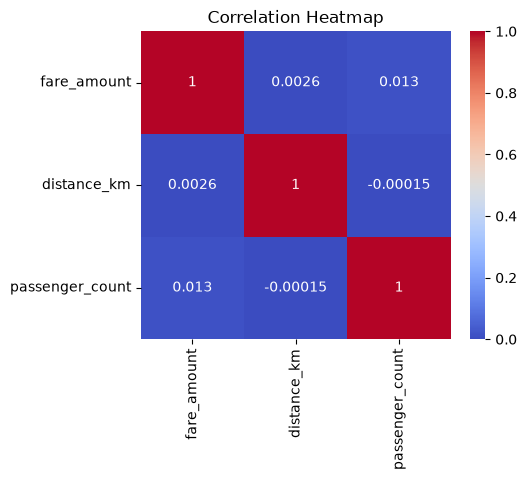

In [ ]:
corr_matrix = df[["fare_amount", "distance_km", "passenger_count"]].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Train Regression Models


In [ ]:
# Features and target
X = df[["distance_km", "passenger_count"]]
y = df["fare_amount"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [71]:
# ---- Linear Regression ----
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [72]:
# ---- Random Forest Regression ----
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

### Model Evaluation
Evaluate both models using **RMSE (Root Mean Squared Error)** and **R² (Coefficient of Determination)**.


In [73]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return rmse, r2

rmse_lr, r2_lr = evaluate_model(y_test, y_pred_lr, "Linear Regression")
rmse_rf, r2_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")

In [74]:
comparison = pd.DataFrame(
    {
        "Model": ["Linear Regression", "Random Forest"],
        "RMSE": [rmse_lr, rmse_rf],
        "R² Score": [r2_lr, r2_rf],
    }
)
print("\nModel Comparison:")
print(comparison)


Model Comparison:
               Model      RMSE  R² Score
0  Linear Regression  4.119054  0.000080
1      Random Forest  2.665772  0.581191
